# Notebook 05 - Predictive Modeling and SHAP

This notebook trains predictive models for `Clay_gkg`, `Sand_gkg`, `C_gkg`, and `OM_gkg` on clean NIR and MIR spectra and exports metrics, predictions, and SHAP explainability.

## Quick Start (for new users)

1. Ensure Notebook 04 finished successfully and generated `04_nir_cluster_assignments.csv`, `04_mir_cluster_assignments.csv`, and `04_clustering_metadata.json` in `Outputs/pipeline/`.
2. Run all cells in order.
3. Confirm outputs in `Outputs/pipeline/`: `05_nir_ml_metrics.csv`, `05_mir_ml_metrics.csv`, `05_nir_ml_predictions_test.csv`, `05_mir_ml_predictions_test.csv`, `05_modeling_metadata.json`, and optionally `05_nir_shap_importance.csv` / `05_mir_shap_importance.csv`.
4. Review figures in `Outputs/pipeline/Figures/`: `05_best_r2_by_target.png`, `05_best_r2_ccc_by_target_by_domain.png`, optional `05_shap_top_features_{domain}_{target}.png`, and `05_pred_vs_obs_{domain}_{target}.png`.
5. Review `05_user_report.txt` for a plain-language summary of model quality and runtime.
6. If upstream artifacts are missing, rerun Notebooks 02 to 04 using the same output folder before retrying.
7. If dependencies are missing, run `launch_pipeline_vscode.bat` and reopen VS Code.

In [1]:
import importlib.util
import sys

RUNTIME_PACKAGES = {
    'numpy': 'numpy',
    'pandas': 'pandas',
    'matplotlib': 'matplotlib',
    'scipy': 'scipy',
    'scikit-learn': 'sklearn',
    'cubist': 'cubist',
}

missing_packages = [pkg_name for pkg_name, module_name in RUNTIME_PACKAGES.items() if importlib.util.find_spec(module_name) is None]
if missing_packages:
    print('Missing dependencies detected:')
    for package_name in missing_packages:
        print(f'  - {package_name}')
    raise RuntimeError(
        'This notebook cannot continue because required packages are missing. '
        'Run launch_pipeline_vscode.bat from the repository root, reopen VS Code, and run this notebook again.'
    )

if '.venv' not in str(sys.executable).lower():
    print('Warning: active interpreter is not .venv. For non-technical users, run launch_pipeline_vscode.bat and reopen VS Code.')
else:
    print('Environment check passed: .venv interpreter detected and required packages are available.')

if importlib.util.find_spec('shap') is None:
    print('Note: SHAP is optional. Models will run, but SHAP outputs will be skipped.')

Environment check passed: .venv interpreter detected and required packages are available.


## Theoretical Framework

This notebook implements **quantitative prediction of soil attributes** from NIR and MIR spectra using machine-learning models. The approach follows the quantitative soil spectroscopy paradigm discussed in **Wadoux et al. (2021)** and **Fabricio et al. (2015)**, where diffuse reflectance is treated as an indirect predictor of soil properties through statistical calibration.

**Target variables:** `C_gkg`, `Clay_gkg`, `OM_gkg`, `Sand_gkg` - four soil properties commonly modeled with NIR and MIR spectroscopy in Brazilian soil spectroscopy literature (**Dematte et al., 2022**; **Fabricio et al., 2015**).

**Sequence guard:** requires `02_nir_clean.csv`, `02_mir_clean.csv`, `04_nir_cluster_assignments.csv`, `04_mir_cluster_assignments.csv`, and `04_clustering_metadata.json`.

**Model comparison:** the notebook now evaluates PLSR, RandomForest, Cubist, and HistGradientBoosting (when available) and reports both **R2** and **CCC** to compare predictive accuracy and agreement.

In [2]:
import time
from pathlib import Path
import sys
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cross_decomposition import PLSRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

ROOT = Path.cwd().resolve().parent if Path.cwd().name.lower() == 'notebooks' else Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

from spectral_pipeline_utils import get_spectral_columns, run_stamp, write_json

OUTPUT_SUBFOLDER = 'pipeline'
OUTPUT_DIR = ROOT / 'Outputs' / OUTPUT_SUBFOLDER
FIG_DIR = OUTPUT_DIR / 'Figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

DOMAIN_CONFIG = {
    'nir': {
        'clean_path': OUTPUT_DIR / '02_nir_clean.csv',
        'cluster_path': OUTPUT_DIR / '04_nir_cluster_assignments.csv',
    },
    'mir': {
        'clean_path': OUTPUT_DIR / '02_mir_clean.csv',
        'cluster_path': OUTPUT_DIR / '04_mir_cluster_assignments.csv',
    },
}

required_files = [
    DOMAIN_CONFIG['nir']['clean_path'],
    DOMAIN_CONFIG['nir']['cluster_path'],
    DOMAIN_CONFIG['mir']['clean_path'],
    DOMAIN_CONFIG['mir']['cluster_path'],
    OUTPUT_DIR / '04_clustering_metadata.json',
]
for file in required_files:
    if not file.exists():
        raise FileNotFoundError(
            f'Missing upstream artifact: {file}. Run Stage 04 first using the same output folder.'
        )

# Execution mode
# FAST_MODE = True  -> quick validation only
# FAST_MODE = False -> final run for reporting
FAST_MODE = False

if FAST_MODE:
    CV_MAX_SAMPLES = 1500
    CV_SPLITS = 2
    RF_TREES = 30
    MAX_SHAP_SAMPLES = 300
    print('FAST_MODE enabled: faster exploratory training')
else:
    CV_MAX_SAMPLES = 4000
    CV_SPLITS = 3
    RF_TREES = 80
    MAX_SHAP_SAMPLES = 800
    print('Final mode: full training run')

shap_spec = importlib.util.find_spec('shap')
if shap_spec is not None:
    shap = importlib.import_module('shap')
    SHAP_AVAILABLE = True
    print(f'SHAP available: v{shap.__version__}')
else:
    SHAP_AVAILABLE = False
    print('SHAP is not available. Modeling will run without SHAP explainability.')

print('Stage 05 preflight passed: required Stage 02/04 artifacts are available for NIR and MIR.')

Final mode: full training run
SHAP available: v0.51.0
Stage 05 preflight passed: required Stage 02/04 artifacts are available for NIR and MIR.


## Block 1 - Model configuration and validation strategy

### Implemented models

The pipeline evaluates three model families with complementary behavior:

| Model | Type | Advantage for spectra | Limitation |
|--------|------|-----------------------|------------|
| **PLSR** | Partial least squares regression | Handles extreme collinearity (NIR bands are highly correlated); projects X and Y into predictive latent components | Linear; cannot capture nonlinear interactions |
| **Random Forest** | Decision-tree ensemble | Nonlinear; robust to outliers; provides variable importance | Slower in very wide feature spaces; can overfit noisy bands |
| **Cubist** | Rule-based regression with committee models | Strong on tabular spectral data; captures nonlinearities while keeping interpretable rules | Can be slower on large feature sets |
| **HistGradientBoosting** | Histogram-based gradient boosting | Fast on wide datasets; supports missing values; often accurate | Higher overfitting risk than RF without regularization |

### Collinearity reduction by spectral grouping (10 nm)

Before model fitting, spectral bands are grouped into **10 nm bins** and averaged within each bin (applied to both NIR and MIR). This follows the practical idea from **Wadoux et al. (2021)** that highly adjacent bands are strongly collinear and can be compressed without losing core predictive structure for many soil attributes.

Operationally, this means Stage 05 now reduces dimensionality by wavelength grouping instead of capping the number of rows for training.

### Validation strategy

The notebook uses **cross-validated K-Fold** on 80% of samples for model selection, and a fixed **20% test set** for final evaluation. Separating model selection from final testing helps avoid data leakage and gives a more realistic external R2 estimate.

### Evaluation metrics

- **R2** (coefficient of determination): fraction of target variance explained by the model.
- **CCC** (Concordance Correlation Coefficient): agreement between observed and predicted values; useful when calibration bias matters.
- **RMSE**: root mean squared error, in target units (g/kg).
- **RRMSE%**: RMSE relative to the target range; useful for cross-target comparisons.
- **RPIQ** (Ratio of Performance to Interquartile distance): robust alternative to RPD for skewed distributions.
- **Bias**: systematic error (predicted minus observed).

### Performance guards

- `CV_MAX_SAMPLES`: cap for cross-validation speed (mode-dependent).
- `RF_TREES`: random forest tree count (mode-dependent).
- `MAX_SHAP_SAMPLES`: cap for SHAP sample size (mode-dependent).
- 10 nm spectral grouping: dimensionality control for collinearity and runtime stability.

In [3]:
t0_total = time.time()

from cubist import Cubist
import cubist._make_data_string as cubist_data_string
import cubist._make_names_string as cubist_names_string
import re

# Enable SHAP for the best model even when it is not a tree model.
# Use aggressive sub-sampling so Cubist/PLSR explanations stay feasible.
NON_TREE_SHAP_ENABLED = True

def _safe_escapes(values):
    text_values = [str(value) for value in values]
    for char in [':', ';', '|']:
        text_values = [value.replace(char, f'\\{char}') for value in text_values]
    return [cubist_names_string.re.escape(value) for value in text_values]

cubist_names_string._escapes = _safe_escapes
cubist_data_string._escapes = _safe_escapes

def concordance_correlation_coefficient(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    if y_true.size == 0 or y_pred.size == 0:
        return np.nan
    mean_true = float(np.nanmean(y_true))
    mean_pred = float(np.nanmean(y_pred))
    var_true = float(np.nanvar(y_true))
    var_pred = float(np.nanvar(y_pred))
    covariance = float(np.nanmean((y_true - mean_true) * (y_pred - mean_pred)))
    denominator = var_true + var_pred + (mean_true - mean_pred) ** 2
    if denominator <= 0 or not np.isfinite(denominator):
        return np.nan
    return (2.0 * covariance) / denominator

def _extract_wavelength_nm(column_name: str):
    match = re.search(r'(\d+(?:\.\d+)?)', str(column_name))
    return float(match.group(1)) if match else None

def _aggregate_spectra_10nm(df_domain: pd.DataFrame, spectral_cols):
    spectral_numeric = df_domain[spectral_cols].apply(pd.to_numeric, errors='coerce')
    parsed = [_extract_wavelength_nm(col) for col in spectral_cols]

    # If wavelengths cannot be parsed reliably, keep the original spectral matrix.
    if any(value is None for value in parsed):
        X_domain = spectral_numeric.to_numpy(dtype=float)
        finite_mean = np.nanmean(X_domain) if np.isfinite(X_domain).any() else 0.0
        X_domain = np.nan_to_num(X_domain, nan=finite_mean, posinf=finite_mean, neginf=finite_mean)
        return X_domain, [str(col) for col in spectral_numeric.columns], False

    bin_ids = np.floor(np.asarray(parsed, dtype=float) / 10.0) * 10.0
    binned = spectral_numeric.T.groupby(bin_ids).mean().T
    binned.columns = [f'{float(wl):.1f}' for wl in binned.columns]

    X_domain = binned.to_numpy(dtype=float)
    finite_mean = np.nanmean(X_domain) if np.isfinite(X_domain).any() else 0.0
    X_domain = np.nan_to_num(X_domain, nan=finite_mean, posinf=finite_mean, neginf=finite_mean)
    return X_domain, [str(col) for col in binned.columns], True

def run_modeling_for_domain(domain: str, clean_path: Path, cluster_path: Path):
    df_domain = pd.read_csv(clean_path, low_memory=False)
    clusters_domain = pd.read_csv(cluster_path)

    _, spectral_cols, _ = get_spectral_columns(df_domain)
    original_spectral_count = len(spectral_cols)
    X_domain, spectral_cols, used_10nm = _aggregate_spectra_10nm(df_domain, spectral_cols)
    if used_10nm:
        print(f'  {domain.upper()}: spectral columns reduced {original_spectral_count} -> {len(spectral_cols)} using 10 nm grouping.')

    targets_domain = ['Clay_gkg', 'Sand_gkg', 'C_gkg', 'OM_gkg']
    targets_domain = [t for t in targets_domain if t in df_domain.columns]
    if not targets_domain:
        raise ValueError(f'No targets were found in the clean {domain.upper()} dataset')

    meta_pred_domain = pd.DataFrame({
        'sample_id': df_domain['ID_Unico'] if 'ID_Unico' in df_domain.columns else np.arange(1, len(df_domain) + 1),
    }).merge(clusters_domain, on='sample_id', how='left')

    models = {
        'PLSR': Pipeline([('scaler', StandardScaler()), ('model', PLSRegression(n_components=8))]),
        'RandomForest': RandomForestRegressor(n_estimators=RF_TREES, random_state=42, n_jobs=-1, max_features='sqrt'),
        'Cubist': Cubist(random_state=42),
    }
    hgb_max_iter = 60 if FAST_MODE else 100
    models['HistGradientBoosting'] = HistGradientBoostingRegressor(random_state=42, max_iter=hgb_max_iter)

    metric_rows_domain = []
    pred_rows_domain = []
    shap_rows_domain = []
    rng_domain = np.random.default_rng(42)

    for target in targets_domain:
        t0_target = time.time()
        print(f'\n-- {domain.upper()} target: {target} --')

        y = pd.to_numeric(df_domain[target], errors='coerce').to_numpy(dtype=float)
        valid = np.isfinite(y)
        X_t, y_t = X_domain[valid], y[valid]
        id_t = meta_pred_domain.loc[valid, 'sample_id'].to_numpy()

        if len(y_t) < 30:
            print(f'  Skipped: insufficient samples ({len(y_t)})')
            continue

        # Sample-count capping is intentionally skipped here; dimensionality is reduced by 10 nm spectral grouping.

        X_train, X_test, y_train, y_test, _, id_test = train_test_split(
            X_t, y_t, id_t, test_size=0.2, random_state=42
        )
        X_train_df = pd.DataFrame(X_train, columns=spectral_cols)
        X_test_df = pd.DataFrame(X_test, columns=spectral_cols)

        best_name = None
        best_r2 = -np.inf
        best_model = None

        for model_name, model in models.items():
            t0_model = time.time()
            kf = KFold(n_splits=CV_SPLITS, shuffle=True, random_state=42)

            X_cv, y_cv = X_train, y_train
            if len(y_cv) > CV_MAX_SAMPLES:
                cv_idx = rng_domain.choice(len(y_cv), size=CV_MAX_SAMPLES, replace=False)
                X_cv, y_cv = X_cv[cv_idx], y_cv[cv_idx]
            X_cv_df = pd.DataFrame(X_cv, columns=spectral_cols)

            try:
                cv_r2 = cross_val_score(model, X_cv_df, y_cv, cv=kf, scoring='r2', n_jobs=1).mean()
            except Exception:
                cv_r2 = np.nan

            model.fit(X_train_df, y_train)
            pred = model.predict(X_test_df)
            pred = pred.ravel() if hasattr(pred, 'ravel') else pred

            r2 = r2_score(y_test, pred)
            rmse = float(np.sqrt(mean_squared_error(y_test, pred)))
            ccc = float(concordance_correlation_coefficient(y_test, pred))
            y_range = float(np.nanmax(y_test) - np.nanmin(y_test)) if len(y_test) else np.nan
            rrmse = (rmse / y_range) * 100 if y_range and np.isfinite(y_range) and y_range > 0 else np.nan
            iqr = float(np.nanpercentile(y_test, 75) - np.nanpercentile(y_test, 25)) if len(y_test) else np.nan
            rpiq = (iqr / rmse) if rmse > 0 and np.isfinite(iqr) else np.nan
            bias = float(np.nanmean(pred - y_test))

            elapsed_model = time.time() - t0_model
            print(f'  {model_name}: R2={r2:.3f} | CV_R2={cv_r2:.3f} | RMSE={rmse:.3f} | {elapsed_model:.1f} s')

            metric_rows_domain.append({
                'domain': domain,
                'target': target,
                'model': model_name,
                'cv_r2_mean': float(cv_r2) if np.isfinite(cv_r2) else np.nan,
                'test_r2': float(r2),
                'ccc': float(ccc) if np.isfinite(ccc) else np.nan,
                'rmse': rmse,
                'rrmse_pct': float(rrmse) if np.isfinite(rrmse) else np.nan,
                'rpiq': float(rpiq) if np.isfinite(rpiq) else np.nan,
                'bias': bias,
                'n_train': int(len(y_train)),
                'n_test': int(len(y_test)),
            })

            if r2 > best_r2:
                best_r2 = r2
                best_name = model_name
                best_model = model

        if best_model is None:
            continue

        best_pred = best_model.predict(X_test_df)
        best_pred = best_pred.ravel() if hasattr(best_pred, 'ravel') else best_pred
        pred_rows_domain.extend([
            {
                'domain': domain,
                'target': target,
                'sample_id': int(sid),
                'y_true': float(yt),
                'y_pred': float(yp),
                'model': best_name,
                'split': 'test',
            }
            for sid, yt, yp in zip(id_test, y_test, best_pred)
        ])

        if SHAP_AVAILABLE:
            try:
                t0_shap = time.time()
                if best_name in {'RandomForest', 'HistGradientBoosting'}:
                    shap_idx = np.arange(len(X_test))
                    if len(shap_idx) > MAX_SHAP_SAMPLES:
                        shap_idx = rng_domain.choice(shap_idx, size=MAX_SHAP_SAMPLES, replace=False)
                    X_shap_df = pd.DataFrame(X_test[shap_idx], columns=spectral_cols)

                    explainer = shap.TreeExplainer(best_model)
                    shap_values = explainer.shap_values(X_shap_df)

                    sv = shap_values if isinstance(shap_values, np.ndarray) else shap_values[0]
                    if hasattr(sv, 'ndim') and sv.ndim == 3:
                        sv = sv[:, :, 0]
                    importance = np.mean(np.abs(sv), axis=0)
                    n_features = min(len(importance), len(spectral_cols))
                    top_idx = np.argsort(importance[:n_features])[::-1][:30]
                    for idx in top_idx:
                        shap_rows_domain.append({
                            'domain': domain,
                            'target': target,
                            'model': best_name,
                            'wavelength': spectral_cols[idx],
                            'mean_abs_shap': float(importance[idx]),
                        })
                    print(f'  SHAP computed in {time.time() - t0_shap:.1f} s')
                elif NON_TREE_SHAP_ENABLED:
                    # Optional and expensive path for Cubist/PLSR winners.
                    shap_idx = np.arange(len(X_test))
                    max_non_tree_samples = min(2, len(shap_idx))
                    if len(shap_idx) > max_non_tree_samples:
                        shap_idx = rng_domain.choice(shap_idx, size=max_non_tree_samples, replace=False)
                    X_shap_df = pd.DataFrame(X_test[shap_idx], columns=spectral_cols)

                    bg_idx = np.arange(len(X_train))
                    max_bg = min(6, len(bg_idx))
                    if len(bg_idx) > max_bg:
                        bg_idx = rng_domain.choice(bg_idx, size=max_bg, replace=False)
                    X_bg_df = pd.DataFrame(X_train[bg_idx], columns=spectral_cols)

                    min_evals = 2 * X_shap_df.shape[1] + 1
                    explainer = shap.Explainer(best_model.predict, X_bg_df, algorithm='permutation')
                    shap_values = explainer(X_shap_df, max_evals=min_evals).values

                    sv = shap_values if isinstance(shap_values, np.ndarray) else shap_values[0]
                    if hasattr(sv, 'ndim') and sv.ndim == 3:
                        sv = sv[:, :, 0]
                    importance = np.mean(np.abs(sv), axis=0)
                    n_features = min(len(importance), len(spectral_cols))
                    top_idx = np.argsort(importance[:n_features])[::-1][:30]
                    for idx in top_idx:
                        shap_rows_domain.append({
                            'domain': domain,
                            'target': target,
                            'model': best_name,
                            'wavelength': spectral_cols[idx],
                            'mean_abs_shap': float(importance[idx]),
                        })
                    print(f'  SHAP (non-tree) computed in {time.time() - t0_shap:.1f} s')
                else:
                    print(f'  SHAP skipped for domain={domain} target={target} model={best_name} (non-tree disabled)')
            except KeyboardInterrupt:
                print(f'  SHAP interrupted for domain={domain} target={target} model={best_name}; continuing without SHAP for this target.')
            except Exception as e:
                print(f'  SHAP could not be computed for domain={domain} target={target} model={best_name}: {e}')

        print(f'  Target {target} completed in {time.time() - t0_target:.1f} s')

    return {
        'domain': domain,
        'df': df_domain,
        'spectral_cols': spectral_cols,
        'X': X_domain,
        'targets': targets_domain,
        'metrics_df': pd.DataFrame(metric_rows_domain),
        'pred_df': pd.DataFrame(pred_rows_domain),
        'shap_df': pd.DataFrame(shap_rows_domain),
        'cluster_path': cluster_path,
    }

try:
    modeling_results = {}
    modeling_results['nir'] = run_modeling_for_domain(
        'nir',
        DOMAIN_CONFIG['nir']['clean_path'],
        DOMAIN_CONFIG['nir']['cluster_path'],
    )
    modeling_results['mir'] = run_modeling_for_domain(
        'mir',
        DOMAIN_CONFIG['mir']['clean_path'],
        DOMAIN_CONFIG['mir']['cluster_path'],
    )

    for domain_name, domain_result in modeling_results.items():
        domain_result['metrics_df'].to_csv(OUTPUT_DIR / f'05_{domain_name}_ml_metrics.csv', index=False)
        domain_result['pred_df'].to_csv(OUTPUT_DIR / f'05_{domain_name}_ml_predictions_test.csv', index=False)
        if not domain_result['shap_df'].empty:
            domain_result['shap_df'].to_csv(OUTPUT_DIR / f'05_{domain_name}_shap_importance.csv', index=False)

    total_seconds = float(time.time() - t0_total)
    print(f'\nTotal training time: {total_seconds:.1f} s')

    metrics_df_all = pd.concat([result['metrics_df'] for result in modeling_results.values()], ignore_index=True)
    pred_df_all = pd.concat([result['pred_df'] for result in modeling_results.values()], ignore_index=True)
    shap_df_all = pd.concat([result['shap_df'] for result in modeling_results.values()], ignore_index=True) if any(
        not result['shap_df'].empty for result in modeling_results.values()
    ) else pd.DataFrame()

    if not metrics_df_all.empty:
        model_order = [model_name for model_name in ['PLSR', 'RandomForest', 'Cubist', 'HistGradientBoosting'] if model_name in metrics_df_all['model'].unique()]
        metric_order = ['test_r2', 'ccc', 'rmse', 'rpiq', 'bias', 'cv_r2_mean']
        display_labels = {
            'test_r2': 'R2',
            'ccc': 'CCC',
            'rmse': 'RMSE',
            'rpiq': 'RPIQ',
            'bias': 'Bias',
            'cv_r2_mean': 'CV_R2',
        }
        model_display_labels = {
            'PLSR': 'PLSR',
            'RandomForest': 'RF',
            'Cubist': 'Cub',
            'HistGradientBoosting': 'HGB',
        }

        summary_table = metrics_df_all.pivot_table(index=['domain', 'target'], columns='model', values=metric_order, aggfunc='max')
        summary_table = summary_table.reindex(
            index=pd.MultiIndex.from_tuples(
                [(domain, target) for domain in ['nir', 'mir'] for target in modeling_results[domain]['targets']],
                names=['domain', 'target'],
            ),
            columns=pd.MultiIndex.from_product([metric_order, model_order]),
        )
        summary_table.columns = pd.MultiIndex.from_tuples(
            [(display_labels.get(metric, metric), model_display_labels.get(model, model)) for metric, model in summary_table.columns],
            names=['Metric', 'Model'],
        )

        print('\nResumen de resultados por dominio y metrica (Metric -> Model):')
        display(summary_table.round(3))
except Exception as exc:
    raise RuntimeError(
        f"Stage 05 modeling failed. Please verify Stage 02/04 outputs and input quality. Details: {exc}"
    ) from exc

  NIR: spectral columns reduced 2151 -> 216 using 10 nm grouping.

-- NIR target: Clay_gkg --
  PLSR: R2=0.671 | CV_R2=0.652 | RMSE=94.948 | 0.2 s
  RandomForest: R2=0.800 | CV_R2=0.777 | RMSE=74.069 | 1.8 s
  Cubist: R2=0.783 | CV_R2=0.765 | RMSE=77.170 | 13.1 s
  HistGradientBoosting: R2=0.808 | CV_R2=0.801 | RMSE=72.541 | 13.1 s
  SHAP computed in 0.7 s
  Target Clay_gkg completed in 28.9 s

-- NIR target: Sand_gkg --
  PLSR: R2=0.618 | CV_R2=0.599 | RMSE=134.683 | 0.3 s
  RandomForest: R2=0.753 | CV_R2=0.733 | RMSE=108.212 | 2.9 s
  Cubist: R2=0.748 | CV_R2=0.717 | RMSE=109.417 | 14.3 s
  HistGradientBoosting: R2=0.767 | CV_R2=0.752 | RMSE=105.019 | 11.2 s
  SHAP computed in 0.7 s
  Target Sand_gkg completed in 29.5 s
  MIR: spectral columns reduced 681 -> 341 using 10 nm grouping.

-- MIR target: Clay_gkg --
  PLSR: R2=0.857 | CV_R2=0.832 | RMSE=72.666 | 0.1 s
  RandomForest: R2=0.887 | CV_R2=0.852 | RMSE=64.669 | 0.5 s
  Cubist: R2=0.896 | CV_R2=0.818 | RMSE=61.862 | 2.6 s
  Hist

PermutationExplainer explainer: 3it [00:12, 12.76s/it]               


  SHAP (non-tree) computed in 12.8 s
  Target Clay_gkg completed in 21.9 s

-- MIR target: Sand_gkg --
  PLSR: R2=0.825 | CV_R2=0.803 | RMSE=100.944 | 0.1 s
  RandomForest: R2=0.839 | CV_R2=0.785 | RMSE=96.926 | 0.6 s
  Cubist: R2=0.847 | CV_R2=0.749 | RMSE=94.401 | 2.6 s
  HistGradientBoosting: R2=0.840 | CV_R2=0.777 | RMSE=96.600 | 5.4 s
  SHAP (non-tree) computed in 7.9 s
  Target Sand_gkg completed in 16.9 s

Total training time: 99.4 s

Resumen de resultados por dominio y metrica (Metric -> Model):


Metric              R2                         CCC                       \
Model             PLSR     RF    Cub    HGB   PLSR     RF    Cub    HGB   
domain target                                                             
nir    Clay_gkg  0.671  0.800  0.783  0.808  0.808  0.882  0.881  0.893   
       Sand_gkg  0.618  0.753  0.748  0.767  0.769  0.850  0.862  0.868   
mir    Clay_gkg  0.857  0.887  0.896  0.888  0.921  0.936  0.945  0.939   
       Sand_gkg  0.825  0.839  0.847  0.840  0.905  0.906  0.918  0.908   

Metric              RMSE           ...   RPIQ          Bias                \
Model               PLSR       RF  ...    Cub    HGB   PLSR     RF    Cub   
domain target                      ...                                      
nir    Clay_gkg   94.948   74.069  ...  2.034  2.164  1.418  3.820 -3.149   
       Sand_gkg  134.683  108.212  ...  1.892  1.971 -3.439 -6.315  1.955   
mir    Clay_gkg   72.666   64.669  ...  4.191  4.029 -7.942 -4.507 -5.146   
       Sand_gkg  100.944   96.926  ...  4.362  4.262  4.429  3.054  8.848   

Metric                  CV_R2                       
Model              HGB   PLSR     RF    Cub    HGB  
domain target                                       
nir    Clay_gkg  1.728  0.652  0.777  0.765  0.801  
       Sand_gkg -4.011  0.599  0.733  0.717  0.752  
mir    Clay_gkg -1.394  0.832  0.852  0.818  0.846  
       Sand_gkg  3.309  0.803  0.785  0.749  0.777  

[4 rows x 24 columns]

## Block 2 - Training loop, evaluation, and prediction export

### SHAP: explainability of the best model per target-domain

**SHAP** (*SHapley Additive exPlanations*) is a post-hoc explainability method based on cooperative game theory. For each prediction, SHAP estimates the contribution of each variable (here, each wavelength band) to the predicted value.

$$\hat{y} = \phi_0 + \sum_{j=1}^{p} \phi_j$$

where $\phi_j$ is the SHAP value for band $j$ (positive increases prediction, negative decreases prediction, and $\phi_0$ is the baseline prediction).

In this stage, SHAP is computed for the **best model selected by test R2** for each `(domain, target)` pair:
- Tree models (`RandomForest`, `HistGradientBoosting`) use `TreeExplainer`.
- Non-tree winners (`Cubist`, `PLSR`) use permutation SHAP with aggressive sampling for runtime control.

### Why SHAP matters in soil spectroscopy

Best-model SHAP helps to:
1. Identify the **most predictive grouped bands** (after 10 nm grouping).
2. Check whether learned relationships are spectrally coherent with known physics rather than artifacts.
3. Compare band-importance profiles across properties and domains.

### Generated artifacts in this block

| File | Content | Pipeline use |
|---------|-----------|-------------------|
| `05_nir_ml_metrics.csv` / `05_mir_ml_metrics.csv` | R2, CV_R2, RMSE, RRMSE, RPIQ, bias by (domain x target x model) | Domain comparison and reporting |
| `05_nir_ml_predictions_test.csv` / `05_mir_ml_predictions_test.csv` | y_true, y_pred, model, sample_id on test samples | Predicted-vs-observed plots and audit |
| `05_nir_shap_importance.csv` / `05_mir_shap_importance.csv` | Top 30 grouped bands by SHAP mean abs value for each (domain x target x best model) | Spectral interpretation and geochemical analysis |

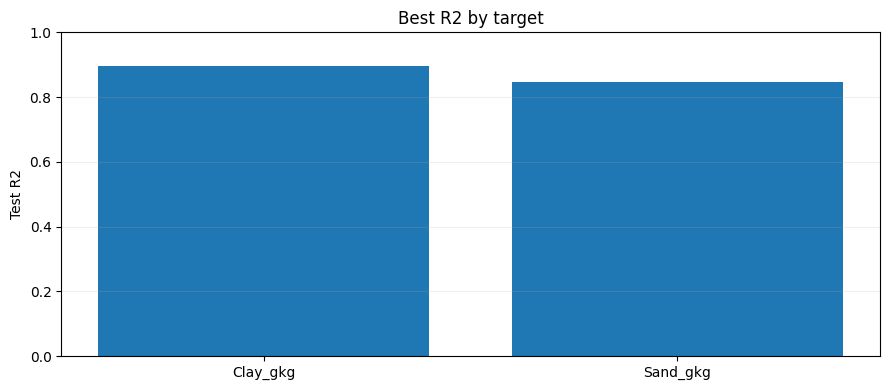

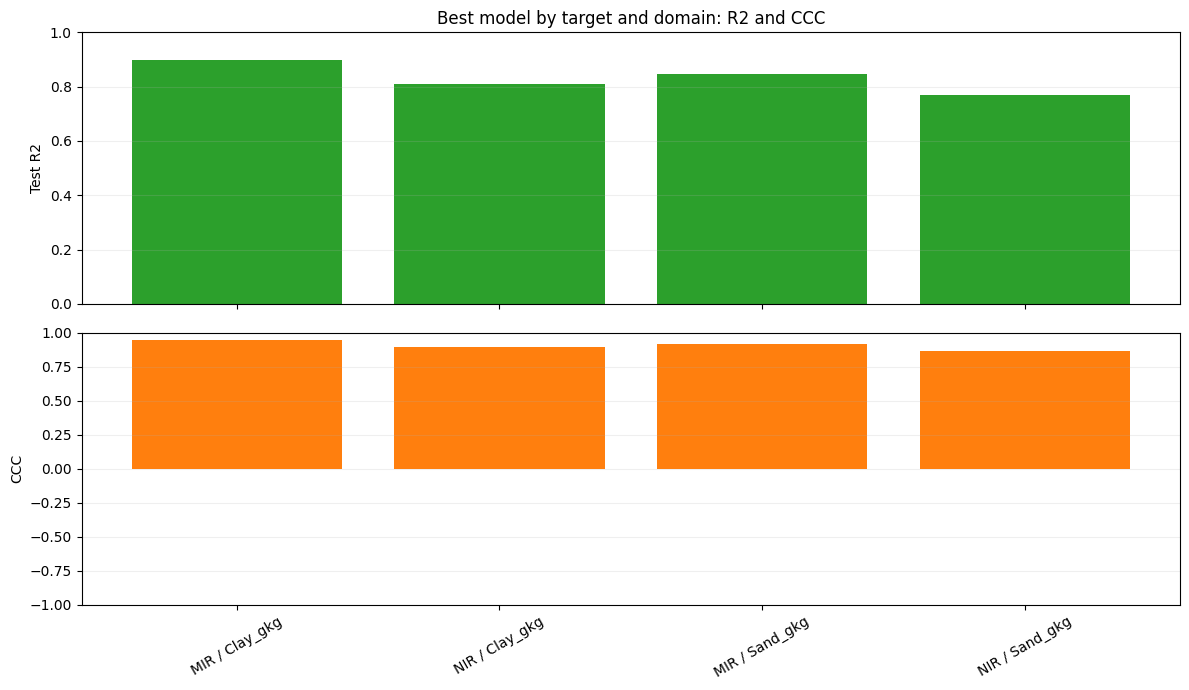

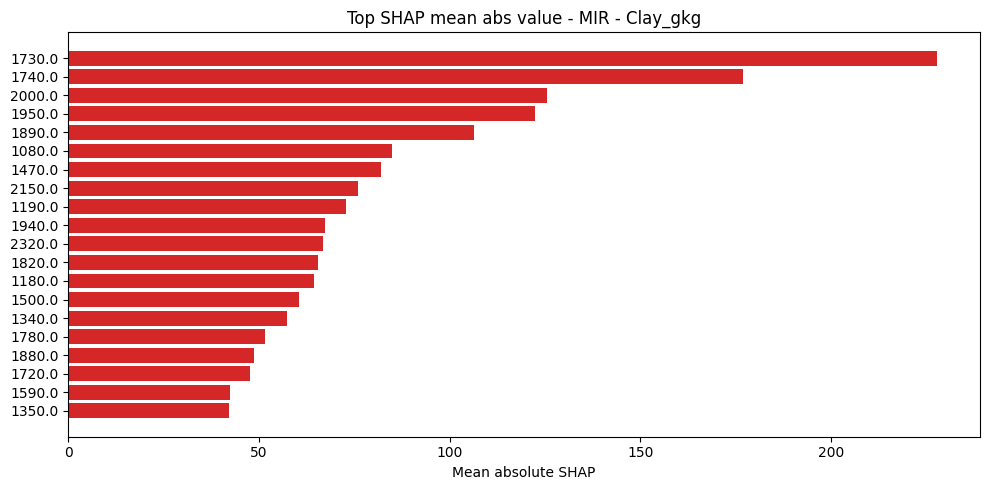

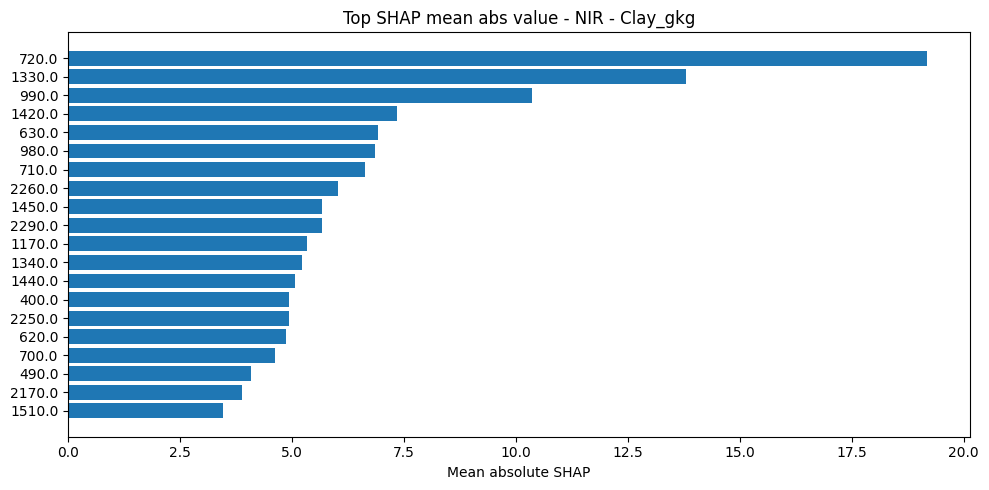

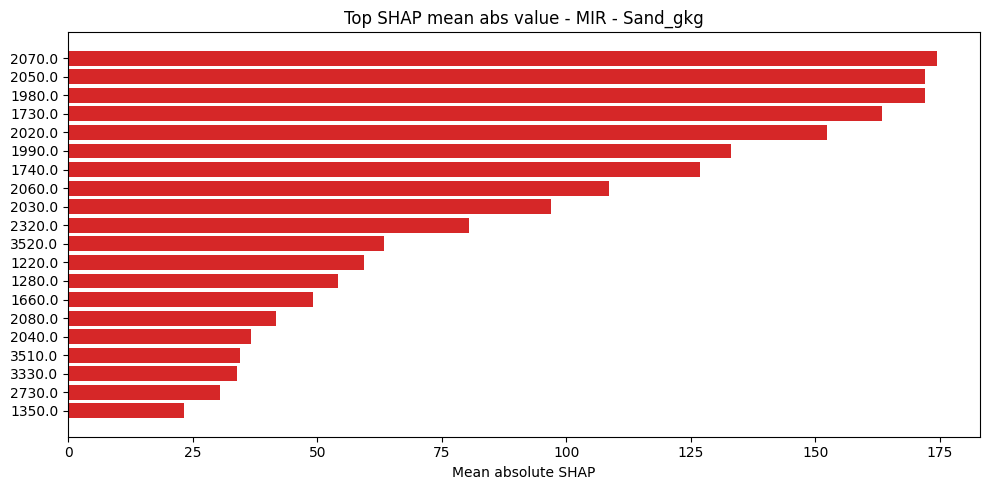

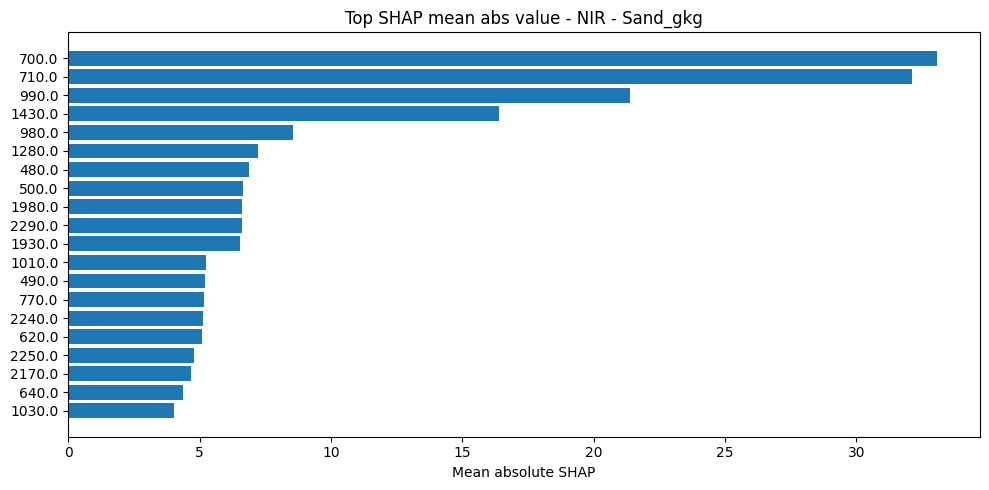

Generated SHAP figures by domain and target:
  - mir_Clay_gkg: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline\Figures\05_shap_top_features_mir_Clay_gkg.png
  - nir_Clay_gkg: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline\Figures\05_shap_top_features_nir_Clay_gkg.png
  - mir_Sand_gkg: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline\Figures\05_shap_top_features_mir_Sand_gkg.png
  - nir_Sand_gkg: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline\Figures\05_shap_top_features_nir_Sand_gkg.png
Final metadata and pipeline manifest saved
Saved user report: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline\05_user_report.txt


In [4]:
best_per_target = (
    metrics_df_all.sort_values(['domain', 'target', 'test_r2'], ascending=[True, True, False])
    .groupby(['domain', 'target'])
    .head(1)
    .reset_index(drop=True)
 )

best_by_target = (
    metrics_df_all.sort_values(['target', 'test_r2'], ascending=[True, False])
    .groupby('target')
    .head(1)
    .reset_index(drop=True)
 )

plt.figure(figsize=(9, 4))
plt.bar(best_by_target['target'], best_by_target['test_r2'], color='tab:blue')
plt.ylim(0, 1)
plt.title('Best R2 by target')
plt.ylabel('Test R2')
plt.grid(axis='y', alpha=0.2)
plt.tight_layout()
fig_r2 = FIG_DIR / '05_best_r2_by_target.png'
plt.savefig(fig_r2, dpi=180)
plt.show()

# Order bars by target with MIR and NIR side-by-side for each attribute.
target_priority = ['Clay_gkg', 'Sand_gkg', 'C_gkg', 'OM_gkg']
targets_present = [target for target in target_priority if target in best_per_target['target'].unique()]
remaining_targets = sorted([target for target in best_per_target['target'].unique() if target not in targets_present])
targets_present.extend(remaining_targets)

ordered_pairs = pd.MultiIndex.from_product(
    [targets_present, ['mir', 'nir']],
    names=['target', 'domain']
 )
plot_df = (
    best_per_target
    .set_index(['target', 'domain'])
    .reindex(ordered_pairs)
    .dropna(subset=['test_r2', 'ccc'])
    .reset_index()
 )
plot_df['label'] = plot_df['domain'].str.upper() + ' / ' + plot_df['target']

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].bar(plot_df['label'], plot_df['test_r2'], color='tab:green')
axes[0].set_ylim(0, 1)
axes[0].set_title('Best model by target and domain: R2 and CCC')
axes[0].set_ylabel('Test R2')
axes[0].grid(axis='y', alpha=0.2)
axes[1].bar(plot_df['label'], plot_df['ccc'], color='tab:orange')
axes[1].set_ylim(-1, 1)
axes[1].set_ylabel('CCC')
axes[1].tick_params(axis='x', rotation=30)
axes[1].grid(axis='y', alpha=0.2)
plt.tight_layout()
fig_r2_domain = FIG_DIR / '05_best_r2_ccc_by_target_by_domain.png'
plt.savefig(fig_r2_domain, dpi=180)
plt.show()

# SHAP plots by (domain, target) pair for clearer interpretation.
fig_shap = None
fig_shap_paths = {}
if not shap_df_all.empty:
    for target_name in targets_present:
        for domain_name in ['mir', 'nir']:
            shap_subset = shap_df_all[
                (shap_df_all['domain'] == domain_name)
                & (shap_df_all['target'] == target_name)
            ].copy()
            if shap_subset.empty:
                continue

            top_shap = (
                shap_subset
                .sort_values('mean_abs_shap', ascending=False)
                .head(20)
                .sort_values('mean_abs_shap', ascending=True)
            )

            plt.figure(figsize=(10, 5))
            plt.barh(
                top_shap['wavelength'].astype(str),
                top_shap['mean_abs_shap'],
                color='tab:blue' if domain_name == 'nir' else 'tab:red'
            )
            plt.title(f'Top SHAP mean abs value - {domain_name.upper()} - {target_name}')
            plt.xlabel('Mean absolute SHAP')
            plt.tight_layout()

            fig_path = FIG_DIR / f'05_shap_top_features_{domain_name}_{target_name}.png'
            plt.savefig(fig_path, dpi=180)
            plt.show()
            fig_shap_paths[f'{domain_name}_{target_name}'] = fig_path

    if fig_shap_paths:
        fig_shap = next(iter(fig_shap_paths.values()))
        print('Generated SHAP figures by domain and target:')
        for shap_key, shap_path in fig_shap_paths.items():
            print(f'  - {shap_key}: {shap_path}')

total_seconds = float(time.time() - t0_total)
meta_payload = run_stamp('05_ml_modeling_shap', {
    'inputs': {
        'nir_clean': str(OUTPUT_DIR / '02_nir_clean.csv'),
        'mir_clean': str(OUTPUT_DIR / '02_mir_clean.csv'),
        'nir_clusters': str(DOMAIN_CONFIG['nir']['cluster_path']),
        'mir_clusters': str(DOMAIN_CONFIG['mir']['cluster_path']),
        'clustering_metadata': str(OUTPUT_DIR / '04_clustering_metadata.json'),
    },
    'timing_seconds': {
        'total': total_seconds,
    },
    'outputs': {
        'nir_metrics': str(OUTPUT_DIR / '05_nir_ml_metrics.csv'),
        'mir_metrics': str(OUTPUT_DIR / '05_mir_ml_metrics.csv'),
        'nir_predictions_test': str(OUTPUT_DIR / '05_nir_ml_predictions_test.csv'),
        'mir_predictions_test': str(OUTPUT_DIR / '05_mir_ml_predictions_test.csv'),
        'nir_shap_importance': str(OUTPUT_DIR / '05_nir_shap_importance.csv') if not modeling_results['nir']['shap_df'].empty else None,
        'mir_shap_importance': str(OUTPUT_DIR / '05_mir_shap_importance.csv') if not modeling_results['mir']['shap_df'].empty else None,
        'fig_r2': str(fig_r2),
        'fig_r2_domain': str(fig_r2_domain),
        'fig_shap': str(fig_shap) if fig_shap else None,
        'fig_shap_by_domain_target': {key: str(path) for key, path in fig_shap_paths.items()} if fig_shap_paths else None,
    },
    'targets': sorted(metrics_df_all['target'].unique().tolist()),
    'domains': ['nir', 'mir'],
    'shap_available': bool(SHAP_AVAILABLE),
})
write_json(OUTPUT_DIR / '05_modeling_metadata.json', meta_payload)

manifest = run_stamp('pipeline_manifest', {
    'stages': [
        str(OUTPUT_DIR / '01_input_qc.json'),
        str(OUTPUT_DIR / '02_processing_metadata.json'),
        str(OUTPUT_DIR / '03_eda_metadata.json'),
        str(OUTPUT_DIR / '04_clustering_metadata.json'),
        str(OUTPUT_DIR / '05_modeling_metadata.json'),
    ]
})
write_json(OUTPUT_DIR / 'pipeline_manifest.json', manifest)

summary_lines = [
    'Notebook 05 User Report',
    '===================',
    '',
    'Input files:',
    f'  - {OUTPUT_DIR / "02_nir_clean.csv"}',
    f'  - {OUTPUT_DIR / "02_mir_clean.csv"}',
    f'  - {DOMAIN_CONFIG["nir"]["cluster_path"]}',
    f'  - {DOMAIN_CONFIG["mir"]["cluster_path"]}',
    f'  - {OUTPUT_DIR / "04_clustering_metadata.json"}',
    '',
    f'SHAP available: {bool(SHAP_AVAILABLE)}',
    f'Execution mode: {"FAST_MODE" if FAST_MODE else "FINAL_MODE"}',
    f'Total runtime (seconds): {total_seconds:.2f}',
    '',
    'Best model per target and domain (by test R2):',
]
for _, row in best_per_target.iterrows():
    summary_lines.append(
        f"  - {row['domain'].upper()} | {row['target']}: {row['model']} | R2={float(row['test_r2']):.4f} | CCC={float(row['ccc']):.4f} | RMSE={float(row['rmse']):.4f}"
    )
summary_lines.extend([
    '',
    'Main outputs',
    f'  - {OUTPUT_DIR / "05_nir_ml_metrics.csv"}',
    f'  - {OUTPUT_DIR / "05_mir_ml_metrics.csv"}',
    f'  - {OUTPUT_DIR / "05_nir_ml_predictions_test.csv"}',
    f'  - {OUTPUT_DIR / "05_mir_ml_predictions_test.csv"}',
    f'  - {FIG_DIR / "05_best_r2_ccc_by_target_by_domain.png"}',
    f'  - {OUTPUT_DIR / "05_modeling_metadata.json"}',
    f'  - {OUTPUT_DIR / "pipeline_manifest.json"}',
    f'  - {OUTPUT_DIR / "05_user_report.txt"}',
])
out_report = OUTPUT_DIR / '05_user_report.txt'
out_report.write_text('\n'.join(summary_lines), encoding='utf-8')

print('Final metadata and pipeline manifest saved')
print(f'Saved user report: {out_report}')

## Block 3 - Result visualization and pipeline closure

### Figure `05_best_r2_by_target.png`
Bar chart of the best test R2 per soil property. It provides a quick comparison of which attributes are most spectrally predictable.

### Figure `05_best_r2_ccc_by_target_by_domain.png`
Two-panel comparison of the best model per target and domain, showing both **R2** and **CCC**. This makes it easier to see whether the best model is also well calibrated, not only accurate.

### Figure `05_pred_vs_obs_{domain}_{target}.png`
Observed vs predicted scatter for the selected target in each domain, including:
- Ideal 1:1 line
- Plus/minus RMSE bands
- Error-magnitude coloring (viridis)
- Top-error points highlighted as potential prediction outliers

Expected interpretation from literature:
- **Clay_gkg** (clay): often strong predictability because of clear diagnostic absorption features.
- **Sand_gkg** (sand): often indirectly predictable through texture relationships with clay.
- **C_gkg / OM_gkg** (carbon / organic matter): commonly moderate to strong, depending on dataset variability and confounding factors.

> **Fabricio et al. (2015)** reported strong performance for clay and sand and moderate to strong performance for carbon using Vis-NIR reflectance in Cerrado soils.

### Figure `05_shap_top_features_{domain}_{target}.png`
Top 20 grouped wavelength combinations by SHAP mean absolute value for each domain-target pair. This helps verify whether the model emphasized spectrally meaningful regions.

> **Madeira Netto (2001)** and **Dematte et al. (2022)** discuss key absorption regions associated with mineral and organic soil constituents.

### `pipeline_manifest.json` - Final pipeline stamp
The manifest stores paths to all 5 stage metadata files (`01_input_qc.json` through `05_modeling_metadata.json`) with execution timestamp. It is the master traceability record for the full pipeline.

This figure helps detect heteroscedasticity (error increasing with target magnitude) and systematic bias (consistent deviation from the 1:1 line).

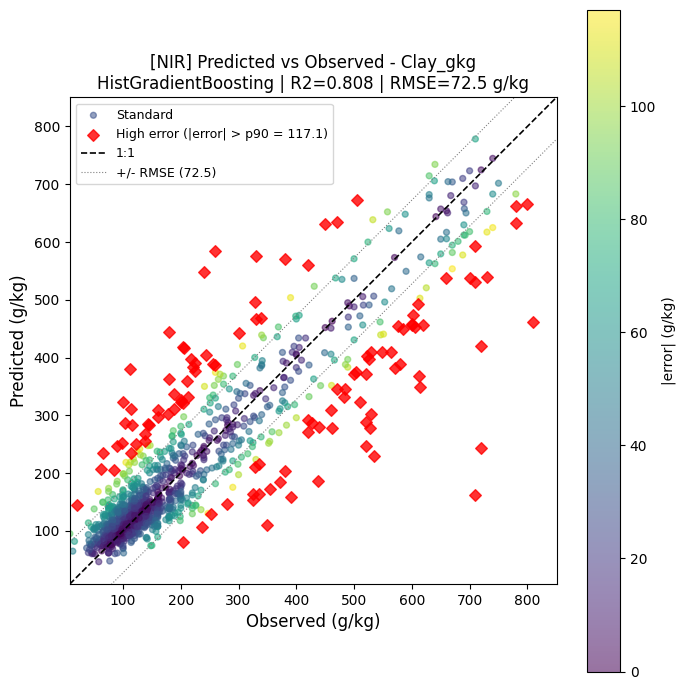

Figure saved: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline\Figures\05_pred_vs_obs_nir_Clay_gkg.png
Standard points: 1005 | High-error points (top 10%): 112


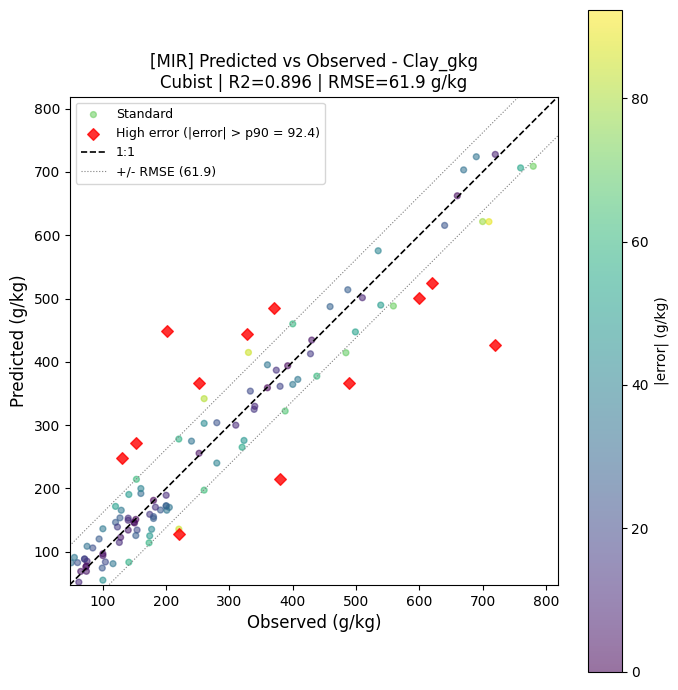

Figure saved: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline\Figures\05_pred_vs_obs_mir_Clay_gkg.png
Standard points: 100 | High-error points (top 10%): 12


In [5]:
# Predicted vs Observed - one chart per domain (NIR / MIR)
if 'modeling_results' not in globals() or not modeling_results:
    raise ValueError('modeling_results is not available. Run the modeling block first.')

for domain_name, domain_result in modeling_results.items():
    metrics_domain = domain_result['metrics_df']
    pred_domain = domain_result['pred_df']

    if metrics_domain.empty or pred_domain.empty:
        print(f'Skipping domain {domain_name}: empty metrics or predictions.')
        continue

    target_plot = metrics_domain.sort_values('test_r2', ascending=False).iloc[0]['target']
    best_model_name = (
        metrics_domain[metrics_domain['target'] == target_plot]
        .sort_values('test_r2', ascending=False)
        .iloc[0]['model']
    )

    subset = pred_domain[pred_domain['target'] == target_plot].copy()
    if subset.empty:
        print(f'Skipping domain {domain_name}: no predictions for target {target_plot!r}.')
        continue

    y_true = subset['y_true'].to_numpy()
    y_pred = subset['y_pred'].to_numpy()

    abs_residuals = np.abs(y_pred - y_true)
    threshold_outlier = np.percentile(abs_residuals, 90)

    lim_min = min(y_true.min(), y_pred.min()) * 0.95
    lim_max = max(y_true.max(), y_pred.max()) * 1.05

    fig, ax = plt.subplots(figsize=(7, 7))

    mask_ok = abs_residuals <= threshold_outlier
    mask_out = abs_residuals > threshold_outlier

    sc = ax.scatter(
        y_true[mask_ok],
        y_pred[mask_ok],
        c=abs_residuals[mask_ok],
        cmap='viridis',
        alpha=0.55,
        s=18,
        label='Standard',
        vmin=0,
        vmax=threshold_outlier,
    )
    ax.scatter(
        y_true[mask_out],
        y_pred[mask_out],
        color='red',
        alpha=0.8,
        s=35,
        marker='D',
        label=f'High error (|error| > p90 = {threshold_outlier:.1f})',
    )

    ax.plot([lim_min, lim_max], [lim_min, lim_max], 'k--', linewidth=1.2, label='1:1')

    rmse_val = float(
        metrics_domain[
            (metrics_domain['target'] == target_plot)
            & (metrics_domain['model'] == best_model_name)
        ]['rmse'].iloc[0]
    )
    ax.plot(
        [lim_min, lim_max],
        [lim_min + rmse_val, lim_max + rmse_val],
        color='gray',
        linewidth=0.8,
        linestyle=':',
        label=f'+/- RMSE ({rmse_val:.1f})',
    )
    ax.plot(
        [lim_min, lim_max],
        [lim_min - rmse_val, lim_max - rmse_val],
        color='gray',
        linewidth=0.8,
        linestyle=':',
    )

    r2_val = float(
        metrics_domain[
            (metrics_domain['target'] == target_plot)
            & (metrics_domain['model'] == best_model_name)
        ]['test_r2'].iloc[0]
    )
    ax.set_xlim(lim_min, lim_max)
    ax.set_ylim(lim_min, lim_max)
    ax.set_xlabel('Observed (g/kg)', fontsize=12)
    ax.set_ylabel('Predicted (g/kg)', fontsize=12)
    ax.set_title(
        f'[{domain_name.upper()}] Predicted vs Observed - {target_plot}\n'
        f'{best_model_name} | R2={r2_val:.3f} | RMSE={rmse_val:.1f} g/kg',
        fontsize=12,
    )
    ax.legend(fontsize=9)
    ax.set_aspect('equal')
    plt.colorbar(sc, ax=ax, label='|error| (g/kg)')
    plt.tight_layout()

    fig_1to1 = FIG_DIR / f'05_pred_vs_obs_{domain_name}_{target_plot}.png'
    plt.savefig(fig_1to1, dpi=180)
    plt.show()
    print(f'Figure saved: {fig_1to1}')
    print(f'Standard points: {mask_ok.sum()} | High-error points (top 10%): {mask_out.sum()}')

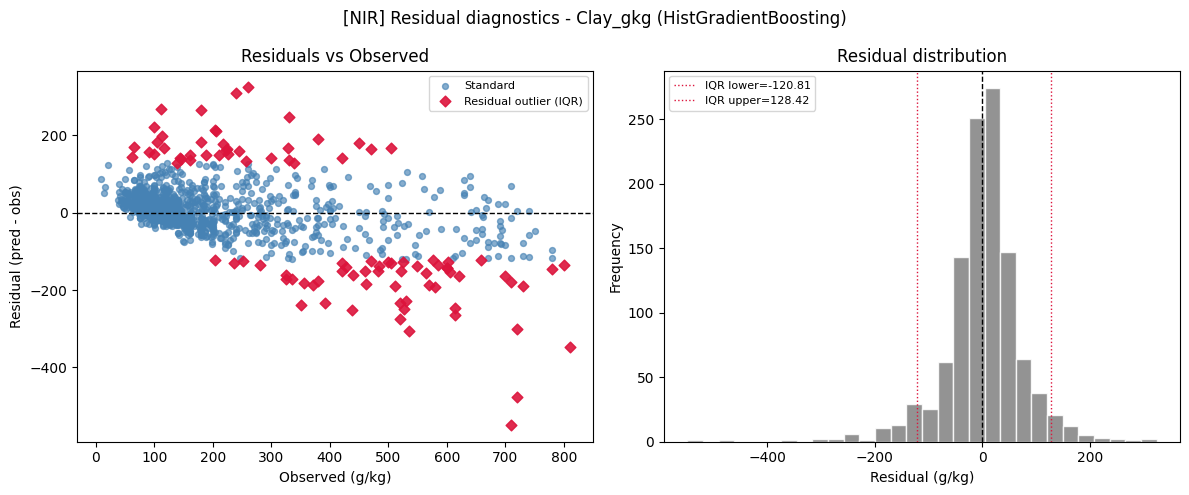

Figure saved: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline\Figures\05_residual_diagnostics_nir_Clay_gkg.png
Outlier records saved: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline\05_residual_outliers_nir_Clay_gkg.csv (n=93)


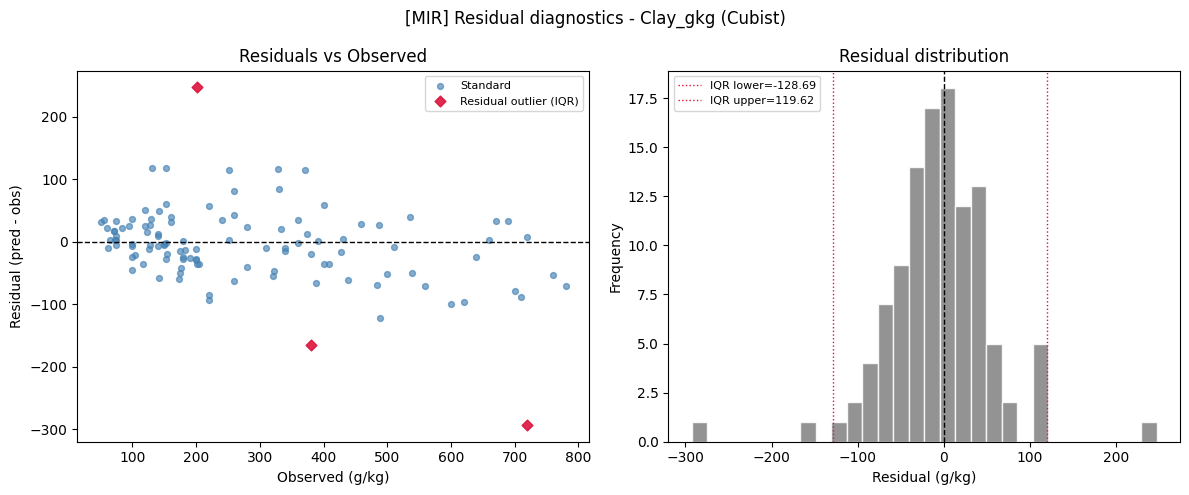

Figure saved: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline\Figures\05_residual_diagnostics_mir_Clay_gkg.png
Outlier records saved: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline\05_residual_outliers_mir_Clay_gkg.csv (n=3)


In [6]:
# Residual diagnostics - one chart per domain (NIR / MIR)
if 'modeling_results' not in globals() or not modeling_results:
    raise ValueError('modeling_results is not available. Run the modeling block first.')

for domain_name, domain_result in modeling_results.items():
    metrics_domain = domain_result['metrics_df']
    pred_domain = domain_result['pred_df']

    if metrics_domain.empty or pred_domain.empty:
        print(f'Skipping residual diagnostics for domain {domain_name}: empty metrics or predictions.')
        continue

    target_plot = metrics_domain.sort_values('test_r2', ascending=False).iloc[0]['target']
    best_model_name = (
        metrics_domain[metrics_domain['target'] == target_plot]
        .sort_values('test_r2', ascending=False)
        .iloc[0]['model']
    )

    subset = pred_domain[pred_domain['target'] == target_plot].copy()
    if subset.empty:
        print(f'Skipping residual diagnostics for domain {domain_name}: no predictions for {target_plot!r}.')
        continue

    subset['residual'] = subset['y_pred'] - subset['y_true']
    q1 = subset['residual'].quantile(0.25)
    q3 = subset['residual'].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    subset['is_outlier'] = (subset['residual'] < lower) | (subset['residual'] > upper)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].scatter(
        subset.loc[~subset['is_outlier'], 'y_true'],
        subset.loc[~subset['is_outlier'], 'residual'],
        color='steelblue',
        alpha=0.65,
        s=18,
        label='Standard',
    )
    if subset['is_outlier'].any():
        axes[0].scatter(
            subset.loc[subset['is_outlier'], 'y_true'],
            subset.loc[subset['is_outlier'], 'residual'],
            color='crimson',
            alpha=0.9,
            s=30,
            marker='D',
            label='Residual outlier (IQR)',
        )
    axes[0].axhline(0, color='black', linestyle='--', linewidth=1)
    axes[0].set_xlabel('Observed (g/kg)')
    axes[0].set_ylabel('Residual (pred - obs)')
    axes[0].set_title('Residuals vs Observed')
    axes[0].legend(fontsize=8)

    axes[1].hist(subset['residual'], bins=30, color='gray', edgecolor='white', alpha=0.85)
    axes[1].axvline(0, color='black', linestyle='--', linewidth=1)
    axes[1].axvline(lower, color='crimson', linestyle=':', linewidth=1, label=f'IQR lower={lower:.2f}')
    axes[1].axvline(upper, color='crimson', linestyle=':', linewidth=1, label=f'IQR upper={upper:.2f}')
    axes[1].set_xlabel('Residual (g/kg)')
    axes[1].set_ylabel('Frequency')
    axes[1].set_title('Residual distribution')
    axes[1].legend(fontsize=8)

    plt.suptitle(
        f'[{domain_name.upper()}] Residual diagnostics - {target_plot} ({best_model_name})',
        fontsize=12,
    )
    plt.tight_layout()

    fig_residual = FIG_DIR / f'05_residual_diagnostics_{domain_name}_{target_plot}.png'
    plt.savefig(fig_residual, dpi=180)
    plt.show()
    print(f'Figure saved: {fig_residual}')

    outliers_df = subset[subset['is_outlier']].copy()
    outlier_file = OUTPUT_DIR / f'05_residual_outliers_{domain_name}_{target_plot}.csv'
    outliers_df.to_csv(outlier_file, index=False)
    print(f'Outlier records saved: {outlier_file} (n={len(outliers_df)})')